# Endterm — CNN Verifier for YOLOv8n Pedestrian Detections

**Student:** Bolatov Bekdaulet, SE-2405 &nbsp;|&nbsp; **Course:** Machine Learning (AMO 3208) &nbsp;|&nbsp; **Instructor:** Mimenbayeva A.B.

This notebook continues my **Assignment 2**. There I built the dataset *PedCrops v1* (21,669 crops from COCO,
3 classes). Here I train and compare deep learning models on it and test the best one on **real YOLOv8n
detections** — the detector of my diploma system *public.safe* (phones as cameras, pedestrian danger zones).

| Task | Section |
|---|---|
| 1 Problem definition | 1 |
| 2 Dataset | 2 |
| 3 Preprocessing (resize, normalize, augmentation, split) | 3 |
| 4 Model development (own CNN + MobileNetV2 transfer learning) | 4 |
| 5 Training with validation | 5 |
| 6 Evaluation (accuracy, precision, recall, F1, confusion matrix, curves) | 7 |
| 7 Improvement (3 hyperparameter configs, augmentation, BatchNorm, Dropout, transfer learning) | 5, 6 |
| 8 Practical application (filter YOLOv8n false positives) | 8 |

The notebook works locally (Apple M1, `mps`) and in Google Colab (GPU). By default `TRAIN = False`:
my saved weights (`models/`) and training histories (`results/histories.json`) are loaded, so the notebook
runs in a few minutes. Set `TRAIN = True` to train all models again (about 1.5 hours on my laptop).

In [1]:
# --- setup: works locally and in Google Colab ---
import os, sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules and not Path("src").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/BekdauletBol/ml-endterm-pedestrian-verifier.git"], check=True)
    os.chdir("ml-endterm-pedestrian-verifier")
TRAIN = False         # True = retrain everything; False = load my saved weights (missing ones are trained)
print("working dir:", Path.cwd().name)

working dir: endterm


In [2]:
import json, time, io, zipfile, dataclasses
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from src.data import CLASSES, IMAGENET_MEAN, IMAGENET_STD, load_split, pick_device, prepare_batch, gpu_augment
from src.models import PedCNN, mobilenet_v2_transfer, set_backbone_trainable, count_params
from src.train import TrainConfig, History, fit, evaluate
from src.evaluate import metrics_dict, report, plot_confusion, plot_history

sns.set_theme(style="whitegrid")
FIG = Path("results/figures"); FIG.mkdir(parents=True, exist_ok=True)
Path("models").mkdir(exist_ok=True)
device = pick_device()
torch.manual_seed(42); np.random.seed(42)
print("torch", torch.__version__, "| device:", device)

torch 2.15.0 | device: mps


## 1. Problem definition

**Type of problem:** image **classification** (supervised, 3 classes) of crops that a person detector produced.

In public.safe the laptop runs **YOLOv8n** on frames from phones. If the box of a "person" is inside a
danger zone, the system writes a *zone_entered* event. YOLOv8n is the smallest YOLO model and it sometimes
calls a bag, a chair or an empty corner a "person". Every such box inside a zone is a **false alarm**.

My model gets the crop of a YOLO box and decides: **pedestrian**, **other_object** or **background**.
Only boxes classified as *pedestrian* are passed to the zone rules.

**Why it matters:** safety staff stop trusting a system with many false alarms; a cheap second check
(a few milliseconds per box) makes the whole system more reliable without a bigger detector.

## 2. Dataset — PedCrops v1 (from Assignment 2)

In [3]:
DATA = Path("data/pedcrops_v1")
stats = json.loads((DATA / "stats.json").read_text())
x_train, y_train, m_train = load_split(DATA, "train")
x_val, y_val, m_val = load_split(DATA, "val")
x_test, y_test, m_test = load_split(DATA, "test")
print("train", tuple(x_train.shape), "val", tuple(x_val.shape), "test", tuple(x_test.shape), "| dtype", x_train.dtype)
dist = pd.DataFrame({s: pd.Series(y.numpy()).map(dict(enumerate(CLASSES))).value_counts() for s, y in
                     [("train", y_train), ("val", y_val), ("test", y_test)]})
dist.loc["total"] = dist.sum(); dist["total"] = dist.sum(axis=1)
dist

train (15260, 3, 128, 128) val (3324, 3, 128, 128) test (3085, 3, 128, 128) | dtype torch.uint8


,train,val,test,total
background,5078,1052,1093,7223
other_object,5019,1132,1072,7223
pedestrian,5163,1140,920,7223
total,15260,3324,3085,21669


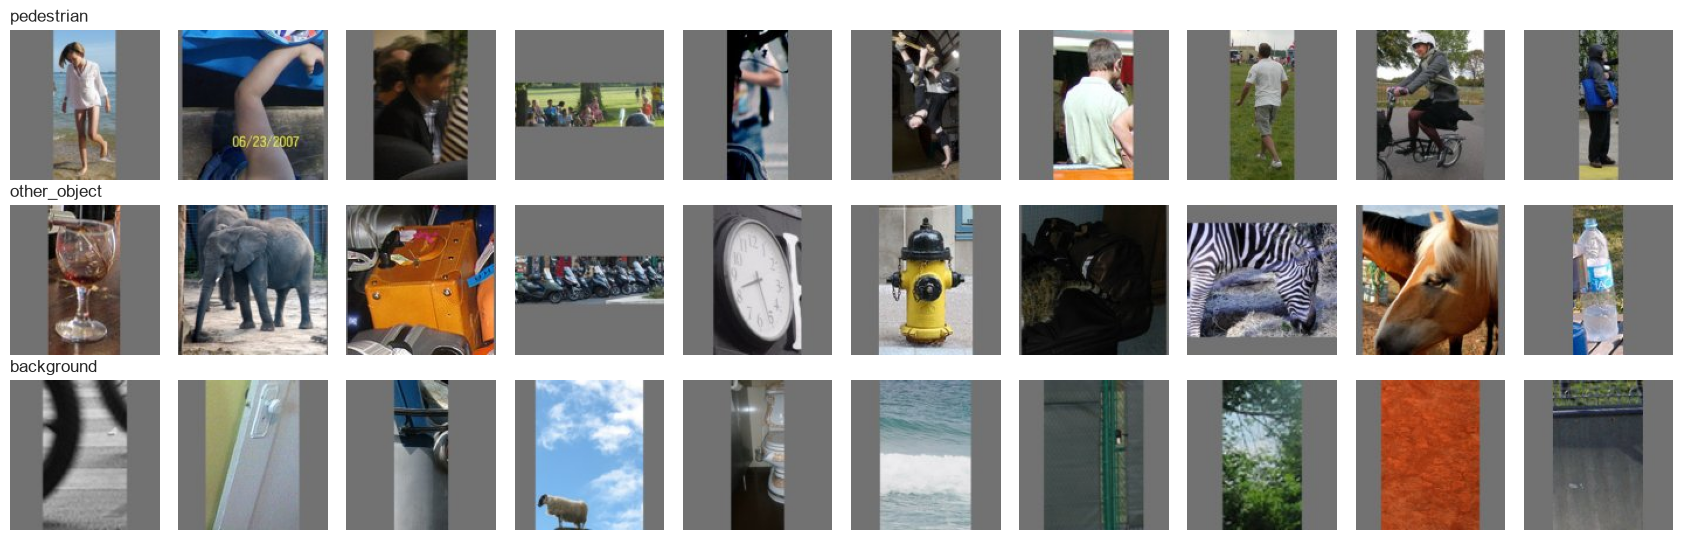

In [4]:
fig, axes = plt.subplots(3, 10, figsize=(17, 5.5))
for r, c in enumerate(CLASSES):
    idx = np.random.default_rng(1).choice(np.where(y_train.numpy() == r)[0], 10, replace=False)
    for k, i in enumerate(idx):
        axes[r, k].imshow(x_train[i].permute(1, 2, 0)); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left")
fig.tight_layout(); fig.savefig(FIG / "dataset_samples.png", dpi=120); plt.show()

## 3. Preprocessing

* **Split:** 70/15/15 by photo, done in Assignment 2 (no photo in two splits → no data leakage).
* **Resize:** crops are stored as 128×128 (letterboxed). The own CNN uses **64×64** (fast enough to try
  several configurations on my laptop), MobileNetV2 uses **128×128**.
* **Normalize:** own CNN – mean/std of the training crops; MobileNetV2 – ImageNet mean/std (because its
  weights were trained with them).
* **Augmentation (train only):** random horizontal flip, rotation ±15°, scaling 0.85–1.15, shift ±10 %,
  brightness/contrast ±20 %. It is done on the GPU for each batch (`src/data.py: gpu_augment`), so every
  epoch sees new versions of the images. Validation and test images are never augmented.

CNN normalization  mean (0.4482, 0.4267, 0.4039) std (0.2063, 0.2004, 0.2072)
MobileNetV2 (ImageNet) mean (0.485, 0.456, 0.406) std (0.229, 0.224, 0.225)


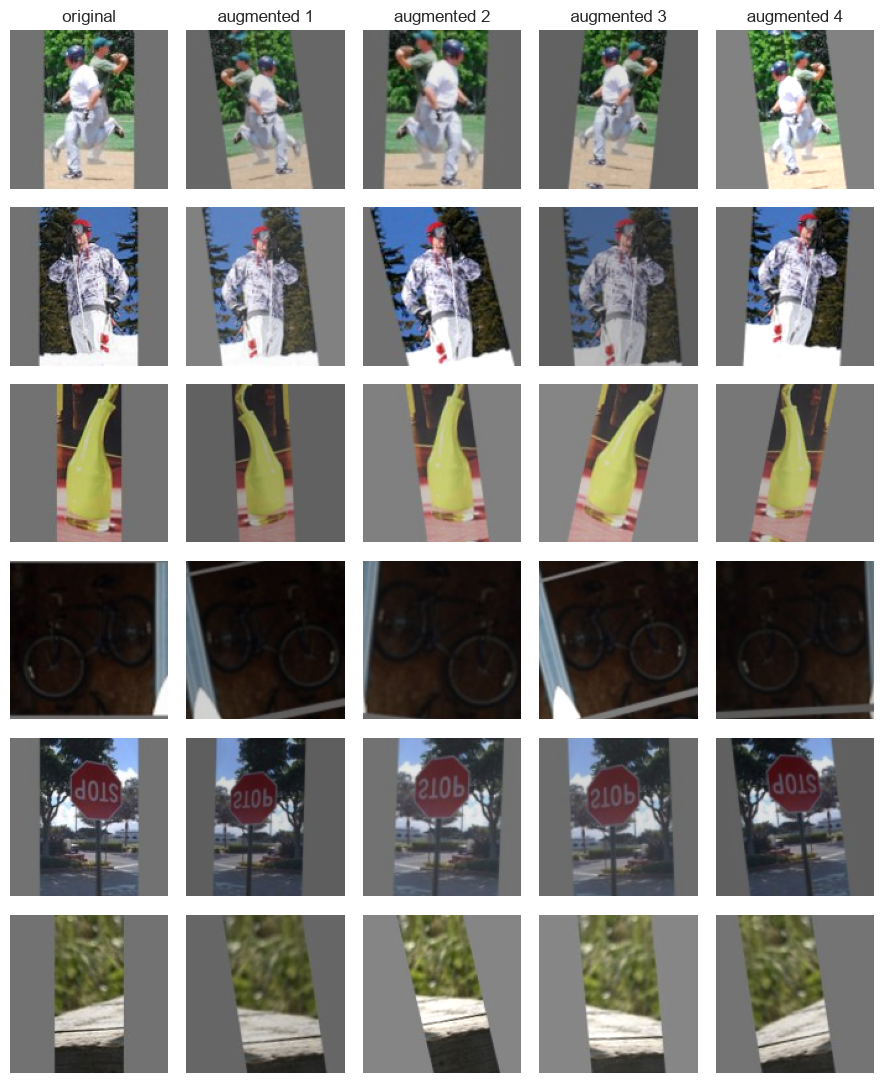

CNN batch: (256, 3, 64, 64) mean 0.122 std 0.858


In [5]:
CNN_MEAN, CNN_STD = tuple(stats["normalization"]["mean"]), tuple(stats["normalization"]["std"])
print("CNN normalization  mean", CNN_MEAN, "std", CNN_STD)
print("MobileNetV2 (ImageNet) mean", IMAGENET_MEAN, "std", IMAGENET_STD)

# augmentation preview: the same 6 crops, original and 4 random augmentations
torch.manual_seed(3)
pick = torch.cat([torch.where(y_train == c)[0][[3, 40]] for c in range(3)])
base = x_train[pick].float() / 255
rows = [base] + [gpu_augment(base, 1.0) for _ in range(4)]
fig, axes = plt.subplots(len(pick), 5, figsize=(9, 11))
for j, batch in enumerate(rows):
    for i in range(len(pick)):
        axes[i, j].imshow(batch[i].permute(1, 2, 0).clamp(0, 1)); axes[i, j].axis("off")
    axes[0, j].set_title("original" if j == 0 else f"augmented {j}")
fig.tight_layout(); fig.savefig(FIG / "augmentation.png", dpi=110); plt.show()

xb = prepare_batch(x_train[:256], device, 64, CNN_MEAN, CNN_STD)
print("CNN batch:", tuple(xb.shape), "mean %.3f std %.3f" % (xb.mean().item(), xb.std().item()))

## 4. Model development

**Model A — own CNN (`PedCNN`, trained from scratch).** 4 convolution blocks (3×3 conv → activation →
2×2 max-pool) with 32, 64, 128, 128 filters, then global average pooling and a dense head. The head
(hidden size, activation, number of hidden layers, weight init) is configurable, so I can run the three
configurations from the task. The activation is used in the conv blocks and in the hidden layer.

**Model B — MobileNetV2 (transfer learning).** Pretrained on ImageNet (1.28 M images). I replace the last
layer with Dropout(0.2) + Linear(1280 → 3). MobileNetV2 is designed for phones, so it fits my system that
runs on a laptop.

In [6]:
for name, net in [("PedCNN (config 1 head)", PedCNN(activation="tanh", hidden_size=64)),
                  ("MobileNetV2 transfer", mobilenet_v2_transfer(pretrained=False))]:
    total, trainable = count_params(net)
    print(f"{name:24s} parameters: {total:,}")
print(PedCNN(activation="tanh", hidden_size=64))

PedCNN (config 1 head)   parameters: 249,283
MobileNetV2 transfer     parameters: 2,227,715
PedCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): Tanh()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): Tanh()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): Tanh()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): Tanh()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (pool): AdaptiveAvgPool2d(output_s

## 5. Training — three hyperparameter configurations (Task 7 table)

All three use **Adam (lr = 0.001)**, **Xavier-uniform** initialization, **1 hidden layer**, cross-entropy
loss, no augmentation, max 30 epochs and **early stopping** on the validation loss (patience 6, the best
epoch is restored).

| Configuration | Optimizer | Initialization | Activation | Hidden layer size | Batch size | Hidden layers |
|---|---|---|---|---|---|---|
| Config 1 | Adam | XavierUniform | tanh | 64 | 1024 | 1 |
| Config 2 | Adam | XavierUniform | tanh | 32 | 128 | 1 |
| Config 3 | Adam | XavierUniform | relu | 32 | 1024 | 1 |

Note: a batch of 1024 images does not fit into the 8 GB memory of my laptop, so the batch is processed
in parts of 256 and the gradients are summed (**gradient accumulation**). The optimizer still makes one step
per 1024 images, so the experiment is the same as with a real batch of 1024.

In [7]:
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
HIST_FILE = RESULTS / "histories.json"
saved = json.loads(HIST_FILE.read_text()) if HIST_FILE.exists() else {}
histories, models_, configs = {}, {}, {}

def run(name, make_model, cfg, weights_path):
    """Train (or load) one model and remember its history."""
    model = make_model()
    if TRAIN or name not in saved or not Path(weights_path).exists():
        hist = fit(model, cfg, x_train, y_train, x_val, y_val, device)
        torch.save(model.state_dict(), weights_path)
        saved[name] = dataclasses.asdict(hist)
        HIST_FILE.write_text(json.dumps(saved))
    else:
        model.load_state_dict(torch.load(weights_path, map_location="cpu"))
        hist = History(**saved[name])
    model.to(device).eval()
    histories[name], models_[name], configs[name] = hist, model, cfg
    return model, hist

CONFIGS = {
    "Config 1": dict(activation="tanh", hidden_size=64, batch_size=1024),
    "Config 2": dict(activation="tanh", hidden_size=32, batch_size=128),
    "Config 3": dict(activation="relu", hidden_size=32, batch_size=1024),
}
for name, c in CONFIGS.items():
    cfg = TrainConfig(name, image_size=64, batch_size=c["batch_size"], epochs=30, patience=6, lr=1e-3,
                      optimizer="Adam", mean=CNN_MEAN, std=CNN_STD)
    run(name, lambda c=c: PedCNN(activation=c["activation"], hidden_size=c["hidden_size"], hidden_layers=1,
                                 init="XavierUniform"), cfg, f"models/pedcnn_{name.replace(' ', '').lower()}.pt")

In [8]:
def summary_row(name, comment=""):
    h, cfg = histories[name], configs[name]
    val_loss, val_acc, _ = evaluate(models_[name], x_val, y_val, cfg, device)
    test_loss, test_acc, probs = evaluate(models_[name], x_test, y_test, cfg, device)
    pred = probs.argmax(1).numpy()
    m = metrics_dict(y_test.numpy(), pred)
    return {"Configuration": name, "Val accuracy": val_acc, "Test accuracy": test_acc, "Test loss": test_loss,
            "Test F1 (macro)": m["f1_macro"], "Best epoch": h.best_epoch, "Epochs run": len(h.train_loss),
            "Training time (s)": h.total_time, "s / epoch": h.total_time / len(h.train_loss), "Comments": comment}

cfg_table = pd.DataFrame([summary_row(n) for n in CONFIGS]).set_index("Configuration")
cfg_table.round(4)

,Val accuracy,Test accuracy,Test loss,Test F1 (macro),Best epoch,Epochs run,Training time (s),s / epoch,Comments
Configuration,,,,,,,,,
Config 1,0.8177,0.8049,0.4658,0.8026,29,30,1152.9485,38.4316,
Config 2,0.8267,0.8049,0.4818,0.8032,12,18,398.7791,22.1544,
Config 3,0.8195,0.8081,0.4633,0.8043,30,30,517.6824,17.2561,


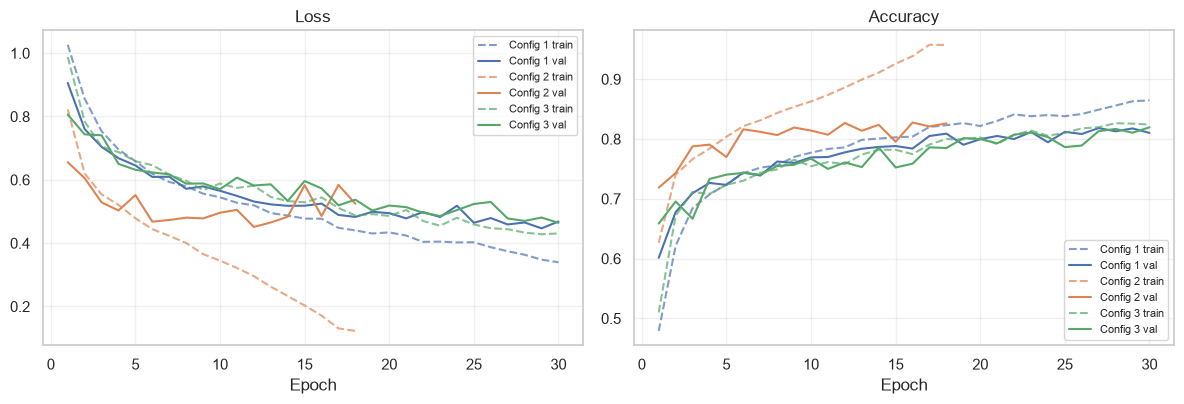

In [9]:
plot_history({n: histories[n] for n in CONFIGS}, FIG / "curves_configs.png"); plt.show()

**Analysis of the three configurations** (table and curves above)

* **All three reach almost the same test accuracy (80.5–80.8 %).** 0.3 percentage points is about 10 of
  3,085 test crops, so on the test set none of the three sets is clearly better. With this small CNN
  and no augmentation the limit is the model and the missing regularization, not these hyperparameters.
* **Batch size (Config 1 vs Config 2) changes *how* the model learns.** Batch 1024 gives only 15 weight
  updates per epoch, batch 128 gives 120. Config 2 reached 79 % validation accuracy already in epoch 4,
  Config 1 needed 17 epochs. But Config 2 also overfits fast: train accuracy went up to 96 % while
  validation stayed at about 83 %, the validation loss was lowest in epoch 12 and early stopping ended the
  run in epoch 18. Configs 1 and 3 were still improving in epoch 29–30 (under-trained, not overfitted).
  The validation curve of Config 2 is also more noisy: a small batch gives a noisier gradient.
* **Activation (Config 1 tanh vs Config 3 relu, both batch 1024).** The curves are almost the same; relu
  is a little better (80.8 % vs 80.5 %, loss 0.463 vs 0.466). The network has only 4 conv layers and Xavier
  initialization keeps tanh in its linear range, so the vanishing-gradient problem of tanh is small here.
* **Hidden size (64 vs 32).** The head (128 → hidden → 3) has 8.5 k or 4.2 k weights out of about 249 k,
  so it has almost no effect.
* **Training time.** All three use the same micro-batch of 256 images, so one epoch costs about the same.
  I timed two epochs of each again, one after another: after the first warm-up epoch it was
  28–38 s per epoch for all three. The different s/epoch in the table
  come from the state of my laptop during each run, not from the hyperparameters. The total time is
  decided by the number of epochs: Config 2 was the fastest only because early stopping ended it in epoch 18.


## 6. Model improvement

Starting from the best configuration I apply three improvement techniques:

1. **Improved CNN** – relu, batch 128, **BatchNorm** after every conv, **Dropout 0.3** in the head,
   **data augmentation**, AdamW with weight decay 1e-4 and a cosine learning-rate schedule.
2. **Transfer learning – MobileNetV2** (ImageNet weights), 128×128 input, augmentation. Stage 1: train
   only the new head for 3 epochs (backbone frozen). Stage 2: fine-tune the whole network with a small
   learning rate (1e-4).

In [10]:
cfg = TrainConfig("Improved CNN", image_size=64, batch_size=128, epochs=30, patience=6, lr=2e-3,
                  optimizer="AdamW", weight_decay=1e-4, augment=1.0, cosine_schedule=True, mean=CNN_MEAN, std=CNN_STD)
run("Improved CNN", lambda: PedCNN(activation="relu", hidden_size=64, hidden_layers=1, batchnorm=True, dropout=0.3),
    cfg, "models/pedcnn_improved.pt");

In [11]:
# MobileNetV2: stage 1 (head only) + stage 2 (full fine-tuning)
def make_mnv2_stage1():
    net = mobilenet_v2_transfer(pretrained=True, dropout=0.2)
    set_backbone_trainable(net, False)
    return net

cfg1 = TrainConfig("MobileNetV2 (frozen)", image_size=128, batch_size=64, micro_batch=64, epochs=3, patience=3,
                   lr=1e-3, optimizer="AdamW", weight_decay=1e-4, augment=1.0, mean=IMAGENET_MEAN, std=IMAGENET_STD)
mnv2, _ = run("MobileNetV2 (frozen)", make_mnv2_stage1, cfg1, "models/mobilenetv2_frozen.pt")

def make_mnv2_stage2():
    net = mobilenet_v2_transfer(pretrained=False, dropout=0.2)
    net.load_state_dict(torch.load("models/mobilenetv2_frozen.pt", map_location="cpu"))
    set_backbone_trainable(net, True)
    return net

cfg2 = TrainConfig("MobileNetV2 (fine-tuned)", image_size=128, batch_size=64, micro_batch=64, epochs=10, patience=4,
                   lr=1e-4, optimizer="AdamW", weight_decay=1e-4, augment=1.0, cosine_schedule=True,
                   mean=IMAGENET_MEAN, std=IMAGENET_STD)
run("MobileNetV2 (fine-tuned)", make_mnv2_stage2, cfg2, "models/mobilenetv2_pedcrops.pt");

[MobileNetV2 (fine-tuned)] epoch  1  train loss 0.3181 acc 0.8782 | val loss 0.2506 acc 0.9049 | 156.4s


[MobileNetV2 (fine-tuned)] epoch  2  train loss 0.2149 acc 0.9183 | val loss 0.2293 acc 0.9185 | 147.6s


[MobileNetV2 (fine-tuned)] epoch  3  train loss 0.1730 acc 0.9347 | val loss 0.2128 acc 0.9275 | 146.8s


[MobileNetV2 (fine-tuned)] epoch  4  train loss 0.1450 acc 0.9453 | val loss 0.2059 acc 0.9323 | 195.5s


[MobileNetV2 (fine-tuned)] epoch  5  train loss 0.1155 acc 0.9544 | val loss 0.1999 acc 0.9308 | 201.2s


[MobileNetV2 (fine-tuned)] epoch  6  train loss 0.0962 acc 0.9638 | val loss 0.2263 acc 0.9284 | 174.5s


[MobileNetV2 (fine-tuned)] epoch  7  train loss 0.0814 acc 0.9689 | val loss 0.1984 acc 0.9341 | 171.9s


[MobileNetV2 (fine-tuned)] epoch  8  train loss 0.0650 acc 0.9763 | val loss 0.2218 acc 0.9335 | 168.4s


[MobileNetV2 (fine-tuned)] epoch  9  train loss 0.0581 acc 0.9784 | val loss 0.2154 acc 0.9362 | 164.0s


[MobileNetV2 (fine-tuned)] epoch 10  train loss 0.0574 acc 0.9797 | val loss 0.1991 acc 0.9395 | 153.8s


## 7. Evaluation on the test set

In [12]:
comments = {
    "Config 1": "tanh, 64 neurons, batch 1024",
    "Config 2": "tanh, 32 neurons, batch 128",
    "Config 3": "relu, 32 neurons, batch 1024",
    "Improved CNN": "+BatchNorm, Dropout, augmentation, cosine LR",
    "MobileNetV2 (frozen)": "transfer learning, only head trained",
    "MobileNetV2 (fine-tuned)": "transfer learning, full fine-tuning",
}
all_rows, preds = [], {}
for name in histories:
    row = summary_row(name, comments.get(name, ""))
    _, _, probs = evaluate(models_[name], x_test, y_test, configs[name], device)
    preds[name] = probs
    m = metrics_dict(y_test.numpy(), probs.argmax(1).numpy())
    row.update({"Precision (macro)": m["precision_macro"], "Recall (macro)": m["recall_macro"],
                "Pedestrian precision": m["precision_pedestrian"], "Pedestrian recall": m["recall_pedestrian"]})
    all_rows.append(row)
results = pd.DataFrame(all_rows).set_index("Configuration")
results.to_csv(RESULTS / "results_table.csv")
results[["Test accuracy", "Precision (macro)", "Recall (macro)", "Test F1 (macro)", "Pedestrian precision",
         "Pedestrian recall", "Test loss", "Training time (s)", "Epochs run"]].round(4)

,Test accuracy,Precision (macro),Recall (macro),Test F1 (macro),Pedestrian precision,Pedestrian recall,Test loss,Training time (s),Epochs run
Configuration,,,,,,,,,
Config 1,0.8049,0.8031,0.8032,0.8026,0.7221,0.7793,0.4658,1152.9485,30
Config 2,0.8049,0.8046,0.8032,0.8032,0.7190,0.7761,0.4818,398.7791,18
Config 3,0.8081,0.8091,0.8075,0.8043,0.7051,0.8109,0.4633,517.6824,30
Improved CNN,0.8535,0.8509,0.8508,0.8502,0.8223,0.8098,0.3696,1030.6018,30
MobileNetV2 (frozen),0.8382,0.8428,0.8381,0.8388,0.8777,0.8424,0.4215,251.1644,3
MobileNetV2 (fine-tuned),0.9284,0.9281,0.9289,0.9284,0.9252,0.9413,0.2137,1681.6654,10


best own CNN: Improved CNN
===== Improved CNN =====
              precision    recall  f1-score   support

  pedestrian     0.8223    0.8098    0.8160       920
other_object     0.8482    0.7976    0.8221      1072
  background     0.8822    0.9451    0.9125      1093

    accuracy                         0.8535      3085
   macro avg     0.8509    0.8508    0.8502      3085
weighted avg     0.8525    0.8535    0.8523      3085



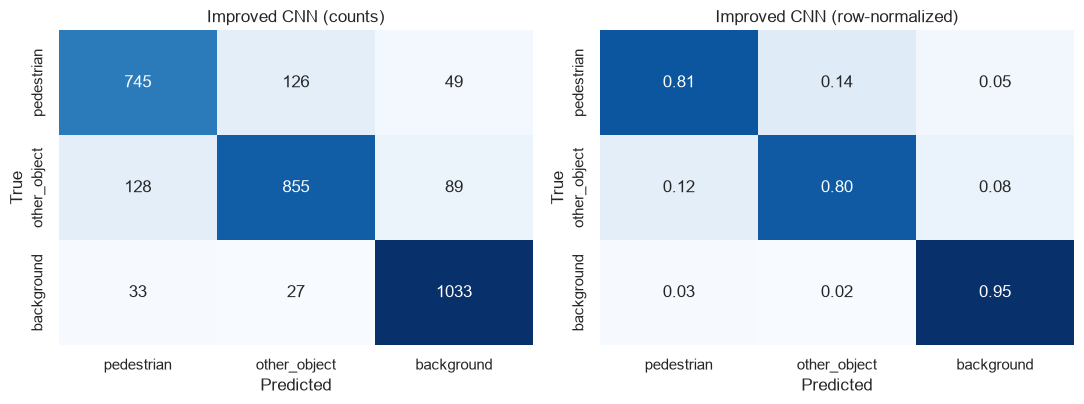

===== MobileNetV2 (fine-tuned) =====
              precision    recall  f1-score   support

  pedestrian     0.9252    0.9413    0.9332       920
other_object     0.9243    0.8993    0.9116      1072
  background     0.9349    0.9460    0.9404      1093

    accuracy                         0.9284      3085
   macro avg     0.9281    0.9289    0.9284      3085
weighted avg     0.9283    0.9284    0.9282      3085



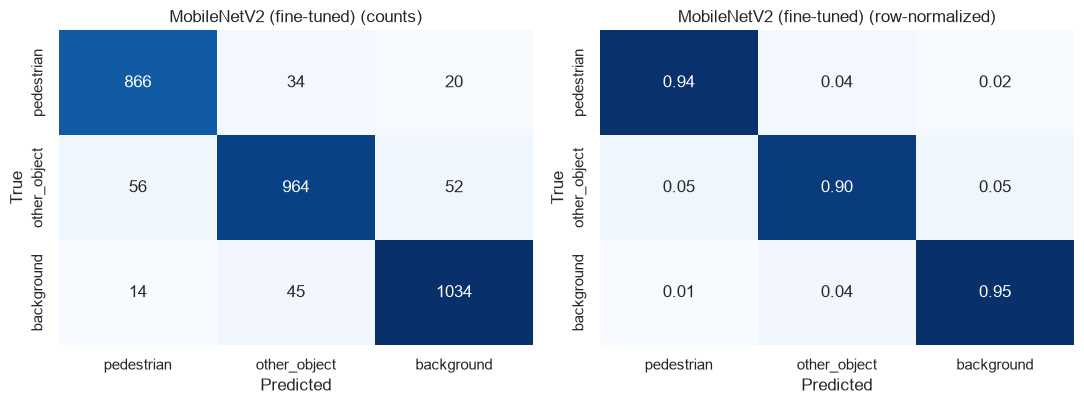

In [13]:
BEST = "MobileNetV2 (fine-tuned)"
best_cnn = results.loc[[n for n in results.index if "MobileNet" not in n], "Test accuracy"].idxmax()
print("best own CNN:", best_cnn)
for name in [best_cnn, BEST]:
    print(f"===== {name} =====")
    print(report(y_test.numpy(), preds[name].argmax(1).numpy()))
    plot_confusion(y_test.numpy(), preds[name].argmax(1).numpy(), name,
                   FIG / ("confusion_mobilenetv2.png" if "MobileNet" in name else "confusion_best_cnn.png")); plt.show()

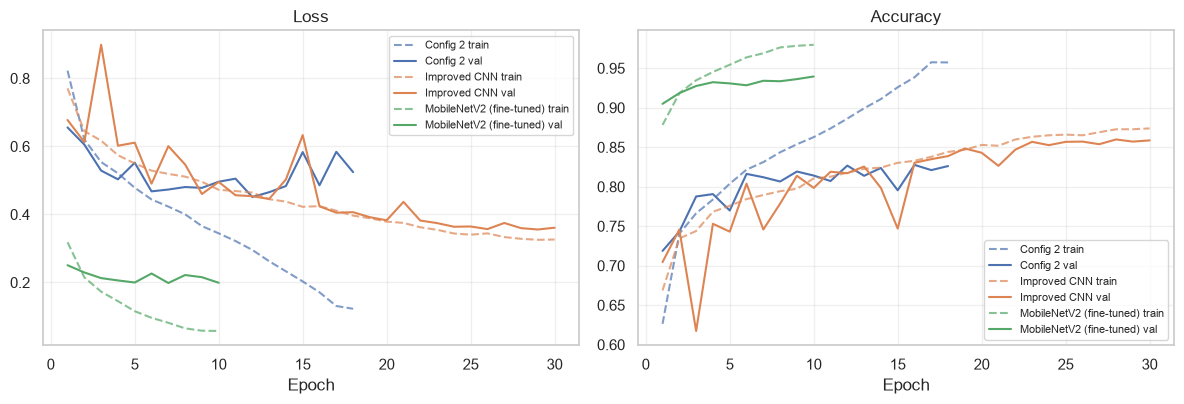

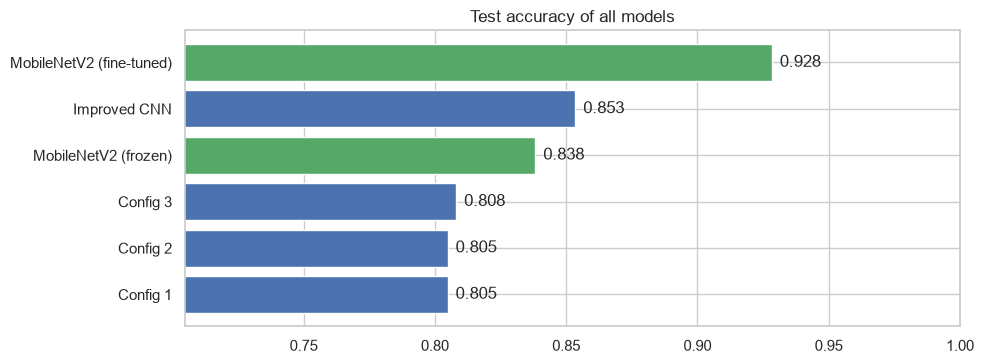

In [14]:
plot_history({n: histories[n] for n in ["Config 2", "Improved CNN", "MobileNetV2 (fine-tuned)"]}, FIG / "curves_improvement.png")
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.8))
r = results["Test accuracy"].sort_values()
ax.barh(r.index, r.values, color=["C0" if "MobileNet" not in n else "C2" for n in r.index])
for i, v in enumerate(r.values): ax.text(v + 0.003, i, f"{v:.3f}", va="center")
ax.set_xlim(max(0, r.min() - 0.1), 1.0); ax.set_title("Test accuracy of all models")
fig.tight_layout(); fig.savefig(FIG / "accuracy_all.png", dpi=150); plt.show()

wrong test crops: 221 of 3085


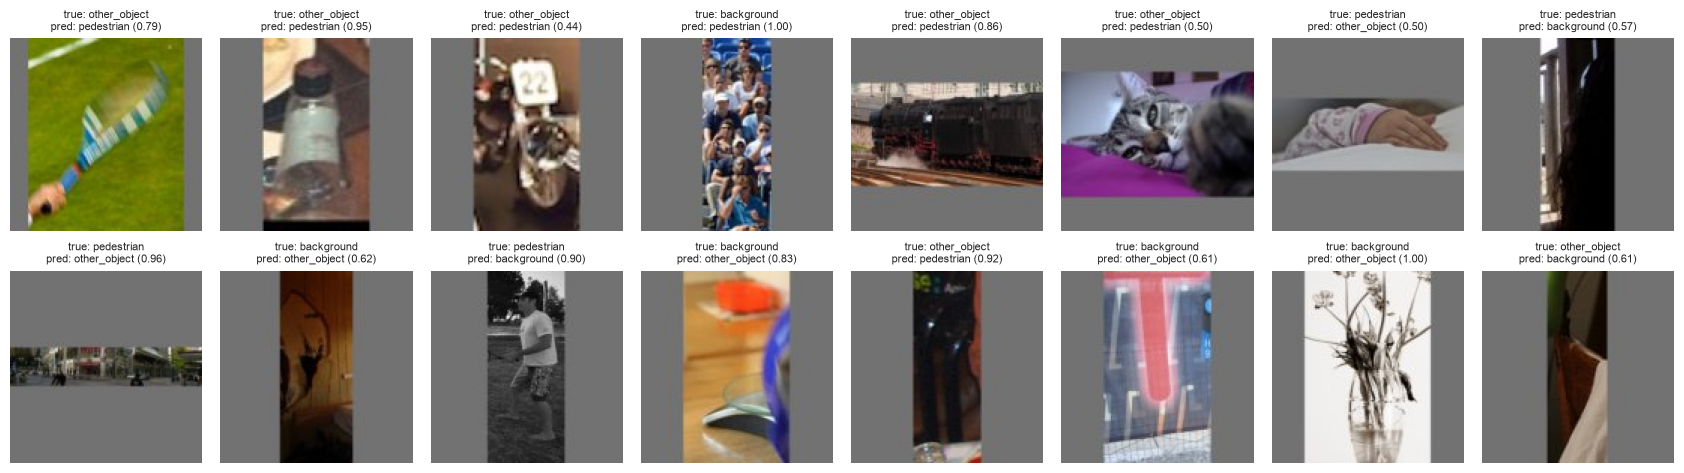

errors of other_object by source category:
source
horse           10
chair            9
potted plant     8
umbrella         8
motorcycle       6
bottle           6
bird             5
cat              4
bench            4
fork             4


In [15]:
# what are the typical mistakes of the best model?
probs = preds[BEST]; pred = probs.argmax(1).numpy(); yt = y_test.numpy()
wrong = np.where(pred != yt)[0]
print("wrong test crops:", len(wrong), "of", len(yt))
show = np.random.default_rng(0).choice(wrong, min(16, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 8, figsize=(17, 5))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(x_test[i].permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"true: {CLASSES[yt[i]]}\npred: {CLASSES[pred[i]]} ({probs[i].max():.2f})", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "errors.png", dpi=110); plt.show()
err = m_test.iloc[wrong]
print("errors of other_object by source category:")
print(err[err.label == "other_object"].source.value_counts().head(10).to_string())

## 8. Practical application — filtering real YOLOv8n false positives

`scripts/make_yolo_detections.py` ran **YOLOv8n** (the same weights as in public.safe, SHA-256
`f59b3d83…`) with the same confidence 0.30 on the **738 test photos**. Each box was compared with the COCO
ground truth: IoU ≥ 0.5 with a real person = true positive (TP), otherwise false positive (FP). The boxes
were cropped exactly like the training crops.

Now the verifier looks at every YOLO box and keeps it only if **P(pedestrian) ≥ threshold**.
A good filter removes many FPs and keeps almost all TPs.

In [16]:
DET = Path("data/yolo_test_detections")
det = pd.read_csv(DET / "detections.csv")
ysum = json.loads((DET / "summary.json").read_text())
print(ysum)
with zipfile.ZipFile(DET / "crops.zip") as zf:
    x_det = torch.from_numpy(np.stack([np.asarray(Image.open(io.BytesIO(zf.read(f"{d}.jpg"))).convert("RGB"))
                                       for d in det.det_id])).permute(0, 3, 1, 2).contiguous()
dummy = torch.zeros(len(det), dtype=torch.long)
_, _, p_det = evaluate(models_[BEST], x_det, dummy, configs[BEST], device)
det["p_ped"] = p_det[:, 0].numpy()
det["pred"] = [CLASSES[i] for i in p_det.argmax(1).numpy()]
# FP types: a box that overlaps a real person a bit (bad localisation / duplicate) vs. no person at all
det["fp_type"] = np.where(det.is_tp, "TP", np.where(det.max_iou_gt >= 0.3, "FP: part of a person", "FP: no person"))
print(det.fp_type.value_counts().to_string())

{'test_images': 738, 'gt_persons': 1557, 'detections': 1184, 'tp': 939, 'fp': 245, 'conf': 0.3, 'iou_tp': 0.5, 'precision': 0.7930743243243243, 'recall': 0.603082851637765}


fp_type
TP                      939
FP: no person           131
FP: part of a person    114


In [17]:
rows = []
for t in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = det.p_ped >= t
    tp_kept, fp_kept = (keep & det.is_tp).sum(), (keep & ~det.is_tp).sum()
    fp_np = (det.fp_type == "FP: no person")
    rows.append({"threshold": t, "TP kept": tp_kept, "FP kept": fp_kept,
                 "TP kept %": tp_kept / det.is_tp.sum() * 100, "FP removed %": 100 - fp_kept / (~det.is_tp).sum() * 100,
                 "'no person' FP removed %": 100 - (keep & fp_np).sum() / fp_np.sum() * 100,
                 "precision": tp_kept / max(1, keep.sum()), "recall": tp_kept / ysum["gt_persons"]})
filt = pd.DataFrame(rows).set_index("threshold")
filt.to_csv(RESULTS / "yolo_filter_table.csv")
filt.round(3)

,TP kept,FP kept,TP kept %,FP removed %,'no person' FP removed %,precision,recall
threshold,,,,,,,
0.0,939,245,100.000,0.000,0.000,0.793,0.603
0.1,922,229,98.190,6.531,7.634,0.801,0.592
0.2,915,222,97.444,9.388,10.687,0.805,0.588
0.3,910,220,96.912,10.204,11.450,0.805,0.584
0.4,906,219,96.486,10.612,12.214,0.805,0.582
0.5,903,213,96.166,13.061,16.031,0.809,0.580
0.6,897,209,95.527,14.694,17.557,0.811,0.576
0.7,889,206,94.675,15.918,19.084,0.812,0.571
0.8,878,199,93.504,18.776,22.137,0.815,0.564


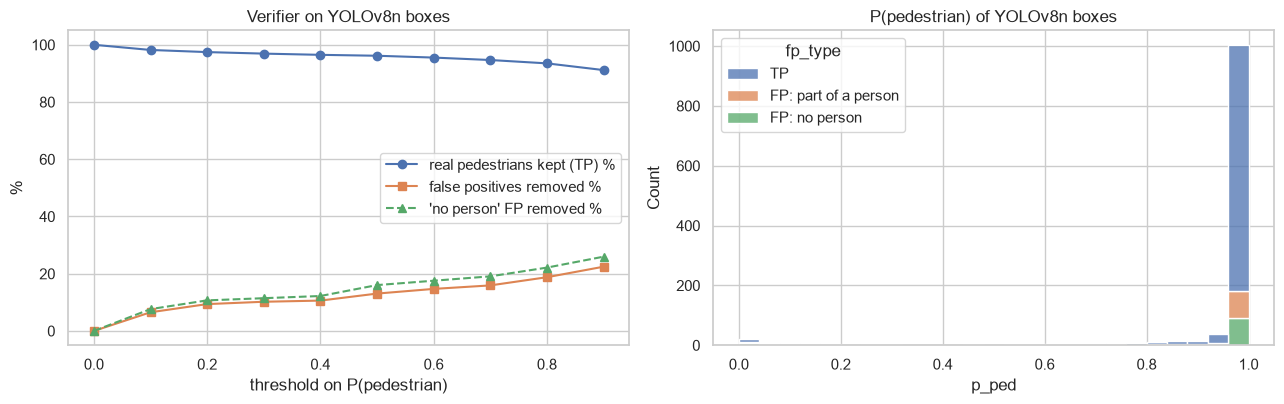

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(filt.index, filt["TP kept %"], "o-", label="real pedestrians kept (TP) %")
axes[0].plot(filt.index, filt["FP removed %"], "s-", label="false positives removed %")
axes[0].plot(filt.index, filt["'no person' FP removed %"], "^--", label="'no person' FP removed %")
axes[0].set_xlabel("threshold on P(pedestrian)"); axes[0].set_ylabel("%"); axes[0].legend(); axes[0].set_title("Verifier on YOLOv8n boxes")
sns.histplot(data=det, x="p_ped", hue="fp_type", bins=25, multiple="stack", ax=axes[1])
axes[1].set_title("P(pedestrian) of YOLOv8n boxes")
fig.tight_layout(); fig.savefig(FIG / "yolo_filter.png", dpi=150); plt.show()

In [19]:
THR = 0.5
for t in [0.0, THR]:
    r = filt.loc[t]
    print(f"threshold {t}: precision {r.precision:.3f}  recall {r.recall:.3f}  FP left {int(r['FP kept'])}  TP lost {int(det.is_tp.sum() - r['TP kept'])}")
# speed of the verifier (batch of 16 crops, like one busy frame)
net, cfgb = models_[BEST], configs[BEST]
xb = prepare_batch(x_det[:16], device, cfgb.image_size, cfgb.mean, cfgb.std)
with torch.no_grad():
    for _ in range(3): net(xb)
    if device.type == "mps": torch.mps.synchronize()
    t0 = time.perf_counter()
    for _ in range(20): net(xb)
    if device.type == "mps": torch.mps.synchronize()
    if device.type == "cuda": torch.cuda.synchronize()
ms = (time.perf_counter() - t0) / 20 * 1000
print(f"verifier time on {device}: {ms:.1f} ms per frame with 16 boxes ({ms/16:.2f} ms per box)")
json.dump({"threshold": THR, "ms_per_16_boxes": ms, "device": str(device),
           "before": filt.loc[0.0].to_dict(), "after": filt.loc[THR].to_dict()}, open(RESULTS / "practical.json", "w"), indent=2)

threshold 0.0: precision 0.793  recall 0.603  FP left 245  TP lost 0
threshold 0.5: precision 0.809  recall 0.580  FP left 213  TP lost 36


verifier time on mps: 32.3 ms per frame with 16 boxes (2.02 ms per box)


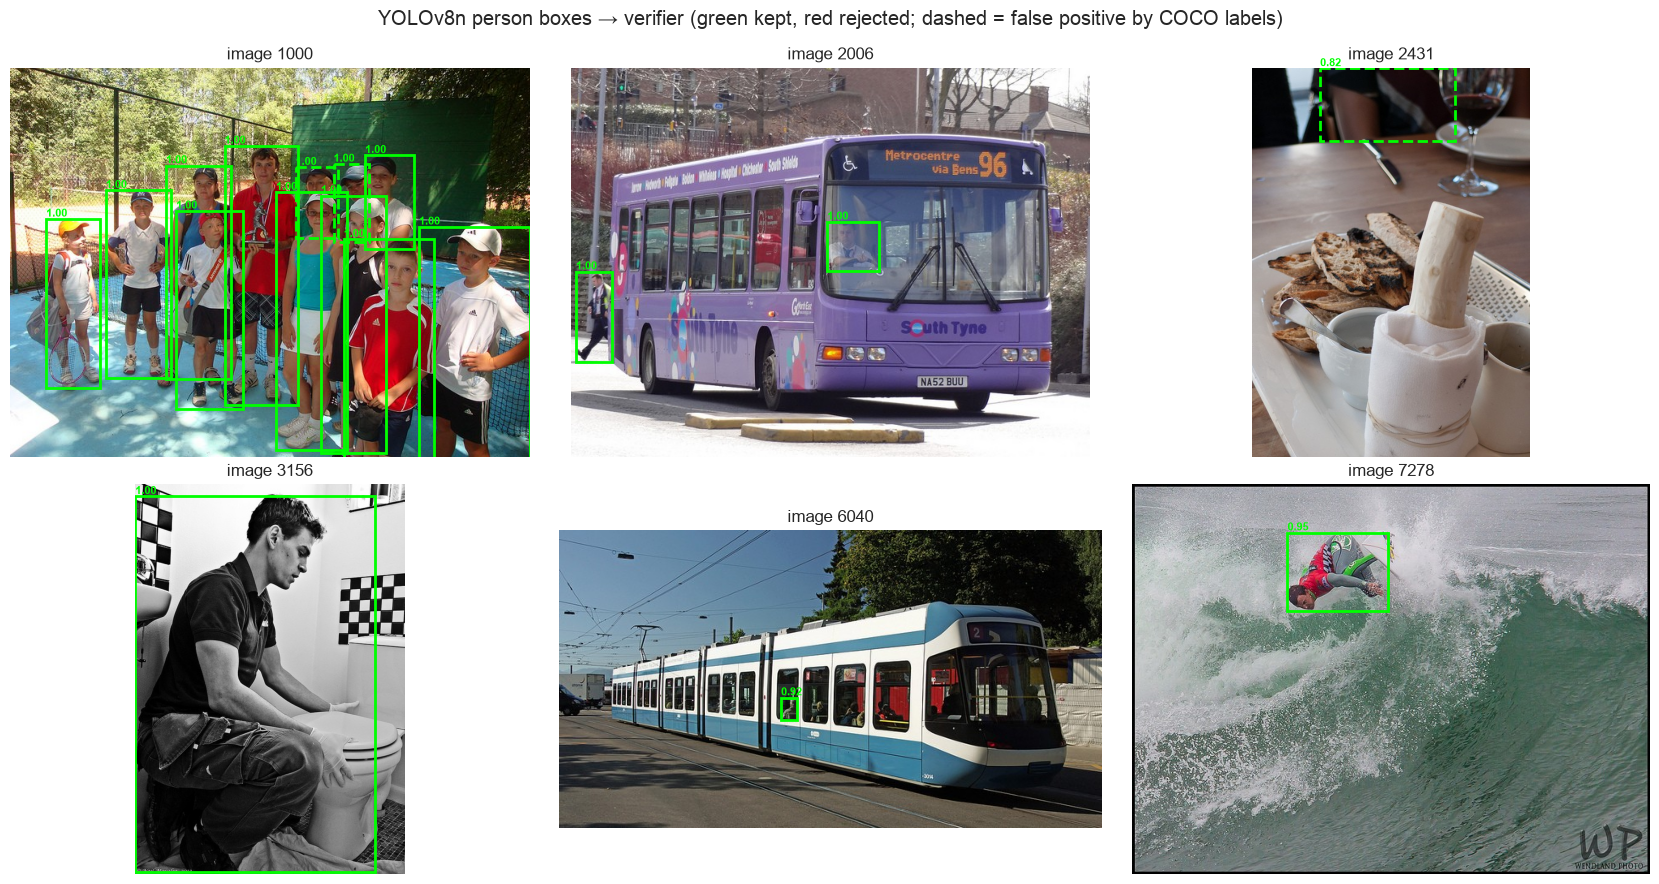

In [20]:
# demo: YOLOv8n boxes on test photos, green = kept by the verifier, red = rejected
import matplotlib.patches as patches
demo = sorted((DET / "demo").glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, p in zip(axes.ravel(), demo):
    ax.imshow(Image.open(p)); ax.axis("off")
    d = det[det.image_id == int(p.stem)]
    for r in d.itertuples():
        ok = r.p_ped >= THR
        ax.add_patch(patches.Rectangle((r.x1, r.y1), r.x2 - r.x1, r.y2 - r.y1, fill=False, lw=2,
                                       color="lime" if ok else "red", ls="-" if r.is_tp else "--"))
        ax.text(r.x1, r.y1 - 3, f"{r.p_ped:.2f}", color="lime" if ok else "red", fontsize=8, weight="bold")
    ax.set_title(f"image {int(p.stem)}")
fig.suptitle("YOLOv8n person boxes → verifier (green kept, red rejected; dashed = false positive by COCO labels)")
fig.tight_layout(); fig.savefig(FIG / "yolo_demo.png", dpi=110); plt.show()

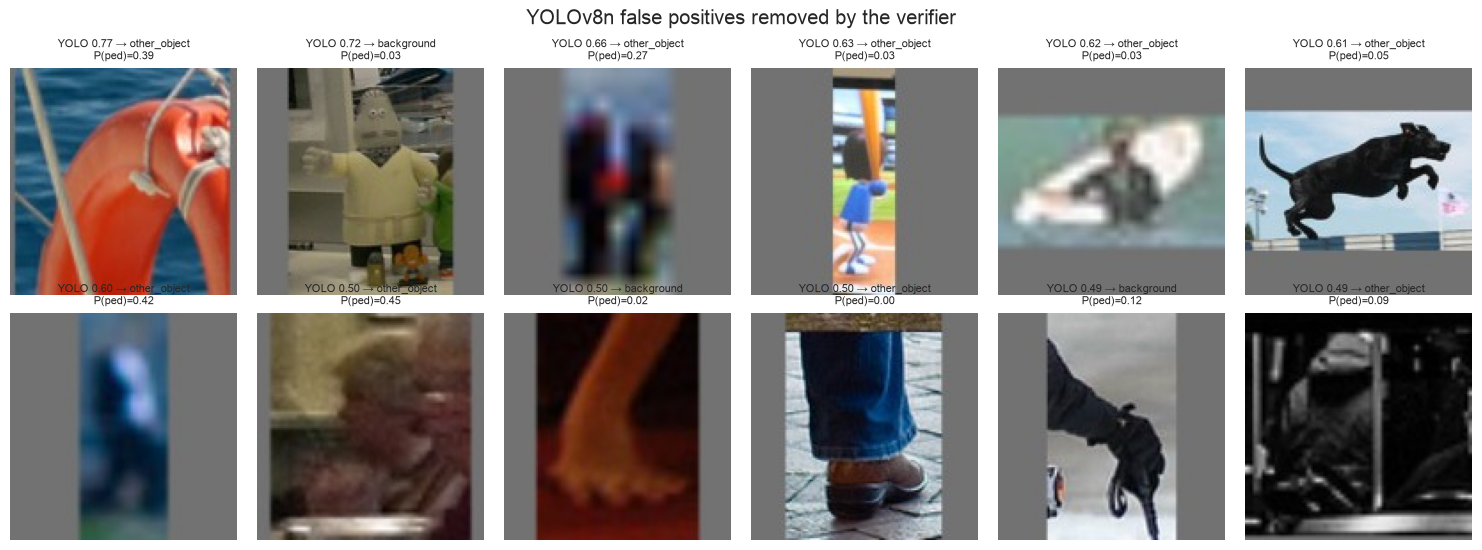

In [21]:
# rejected false positives: what did YOLOv8n think was a person?
fp_rej = det[(~det.is_tp) & (det.p_ped < THR)].sort_values("conf", ascending=False).head(12)
with zipfile.ZipFile(DET / "crops.zip") as zf:
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
    for ax, r in zip(axes.ravel(), fp_rej.itertuples()):
        ax.imshow(Image.open(io.BytesIO(zf.read(f"{r.det_id}.jpg")))); ax.axis("off")
        ax.set_title(f"YOLO {r.conf:.2f} → {r.pred}\nP(ped)={r.p_ped:.2f}", fontsize=8)
fig.suptitle("YOLOv8n false positives removed by the verifier"); fig.tight_layout()
fig.savefig(FIG / "yolo_rejected.png", dpi=110); plt.show()

'no person' FPs kept by the verifier: 110 of 131; showing 40


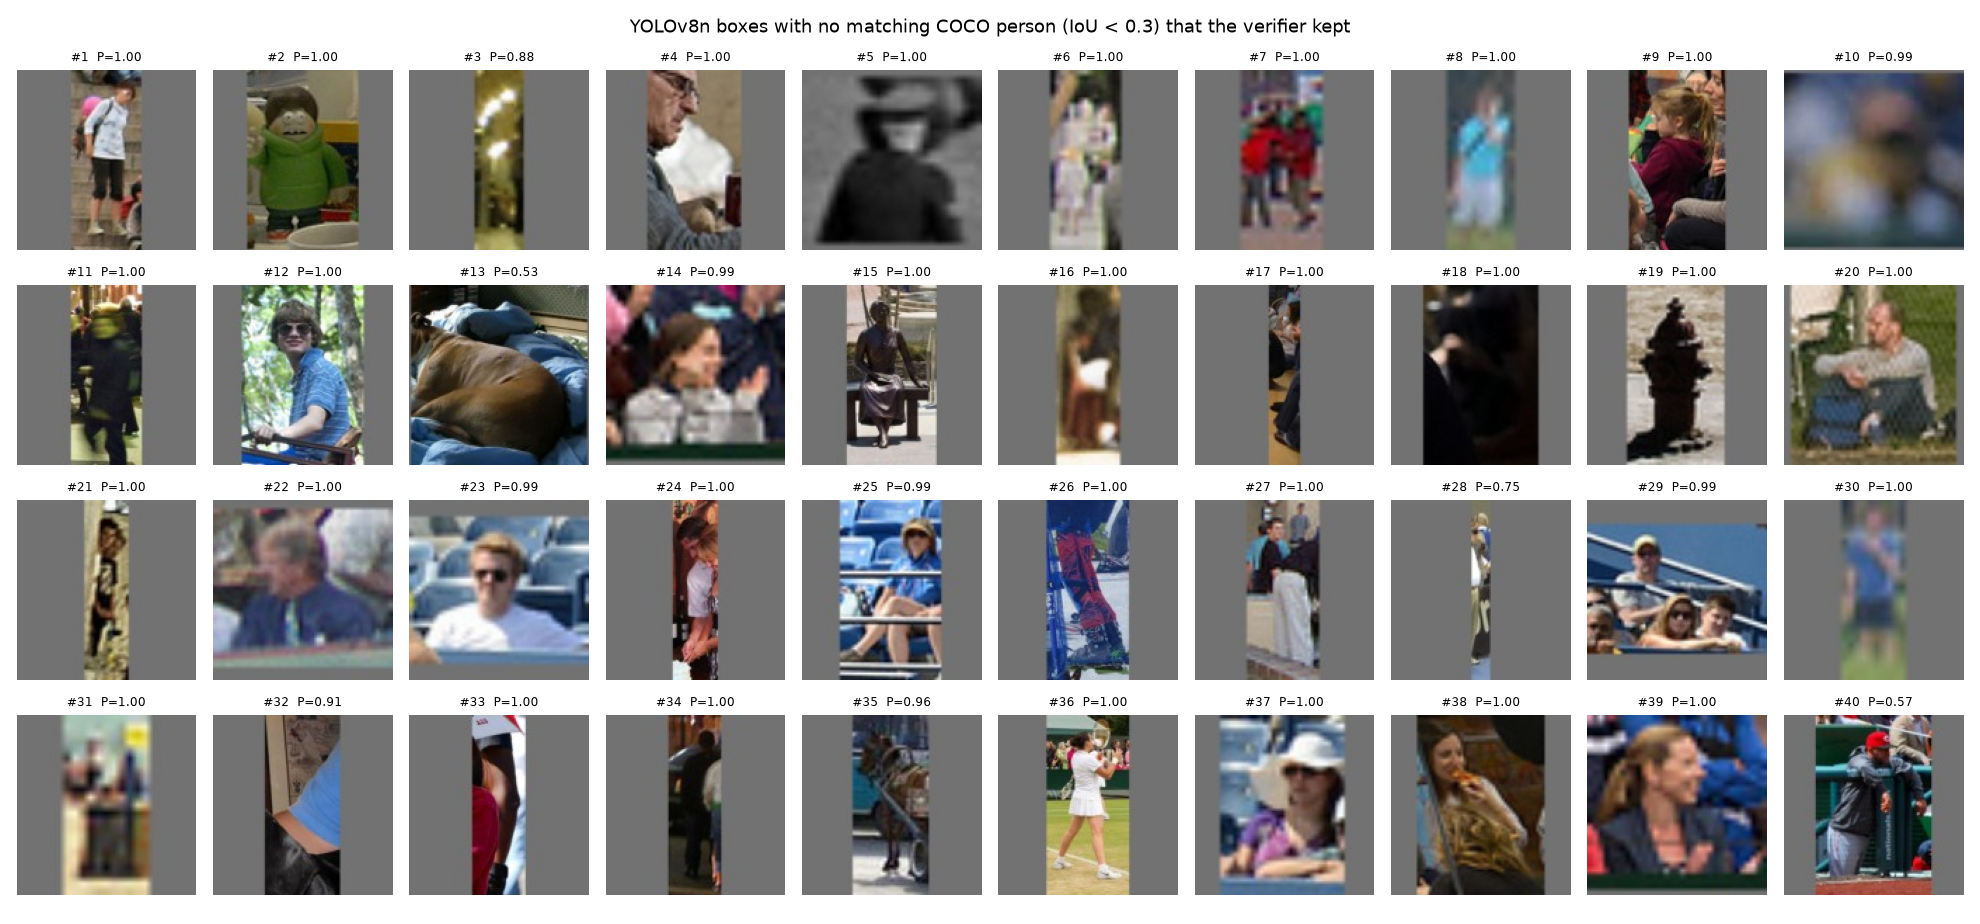

In [22]:
# Manual check: are the "no person" false positives that the verifier KEEPS really not people?
# 40 random ones are shown with a number; I looked at each of them (result in the next cell).
kept_np = det[(det.fp_type == "FP: no person") & (det.p_ped >= THR)].sort_values("det_id")
check = kept_np.sample(min(40, len(kept_np)), random_state=0)
print(f"'no person' FPs kept by the verifier: {len(kept_np)} of {(det.fp_type == 'FP: no person').sum()}; showing {len(check)}")
with zipfile.ZipFile(DET / "crops.zip") as zf:
    fig, axes = plt.subplots(4, 10, figsize=(18, 8.4))
    for k, (ax, r) in enumerate(zip(axes.ravel(), check.itertuples()), 1):
        ax.imshow(Image.open(io.BytesIO(zf.read(f"{r.det_id}.jpg")))); ax.axis("off")
        ax.set_title(f"#{k}  P={r.p_ped:.2f}", fontsize=8)
fig.suptitle("YOLOv8n boxes with no matching COCO person (IoU < 0.3) that the verifier kept")
fig.tight_layout(); fig.savefig(FIG / "kept_fp_check.png", dpi=110); plt.show()

**My manual check of the 40 boxes above** (I looked at every crop):

| What the crop shows | Count | Numbers |
|---|---|---|
| a real person or a part of a person that has **no box in COCO** (spectators, people in a crowd, people at the image border) | 27 | 1, 4, 5, 7, 8, 9, 11, 12, 14, 16, 20, 22–27, 29, 30, 32–34, 36–40 |
| **not a person** – real mistake of YOLOv8n *and* of my verifier | 5 | 2 (toy figure), 13 (dog), 15 (bronze statue), 19 (fire hydrant), 35 (donkey with cart) |
| too small, dark or blurred to decide | 8 | 3, 6, 10, 17, 18, 21, 28, 31 |

So most "false positives" that the verifier keeps are **real people that COCO did not label**. For these
boxes the verifier is right and the COCO ground truth is incomplete. This is why the measured FP reduction
(13 % at threshold 0.5) is small: the real non-person boxes are only a part of the 245 "FPs". The numbers in the
table above are therefore a pessimistic (lower) estimate of what the filter does.


## Conclusion

* Three hyperparameter configurations of my own CNN reach almost the same test accuracy (80.5–80.8 %). The batch
  size changed the speed of learning and the overfitting a lot; activation and hidden size changed little.
* BatchNorm + Dropout + augmentation improved the own CNN to 85.3 %. **Transfer learning with MobileNetV2**
  gave the best model: **92.8 % test accuracy, macro F1 0.928, pedestrian recall 94.1 %**.
* On **real YOLOv8n detections** (threshold 0.5) the verifier removes 13 % of the false positives (245 → 213)
  and loses 3.8 % of the true pedestrians (939 → 903); precision goes from 0.793 to 0.809. The effect is small
  because most of these "false positives" are real people without a COCO label (manual check: 27 of 40).
  The verifier needs about 2 ms per box on my laptop, so it can be added to public.safe behind the existing
  detector interface (`src/verified_detector.py`), but it must be tested on images from the real cameras first.

All numbers are explained in the report (`report/Endterm_Report_Bolatov_Bekdaulet.pdf`).
